In [1]:
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator


In [2]:
generator = InterventionDatasetGenerator(
    function_generator="simplegplvm",
    num_variables=[2],
    sample_size=1000,
    batch_size=1,
    graph_type=["ER"],
    graph_degrees=[1],
    iterations_per_epoch=10,
)

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


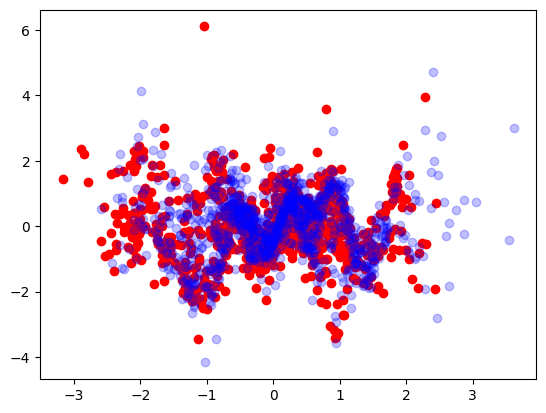

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


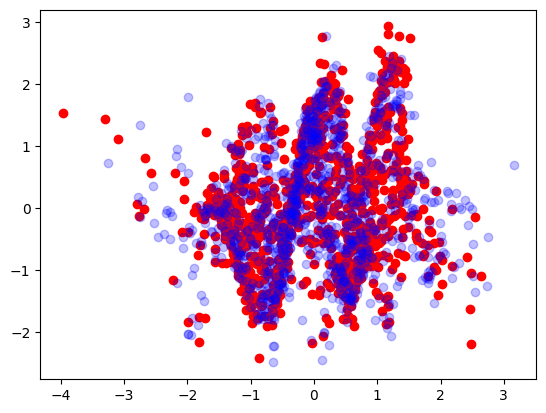

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


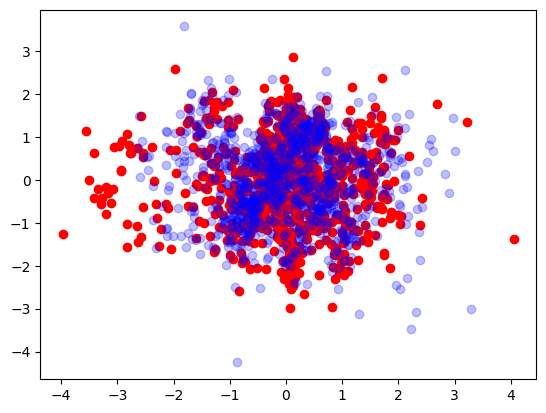

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


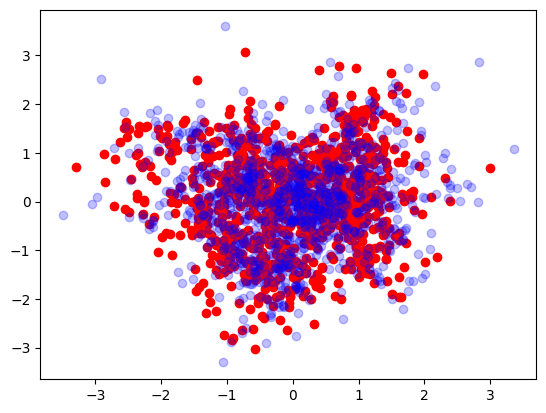

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


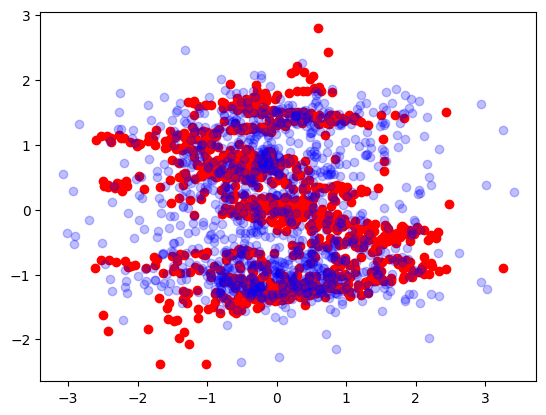

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


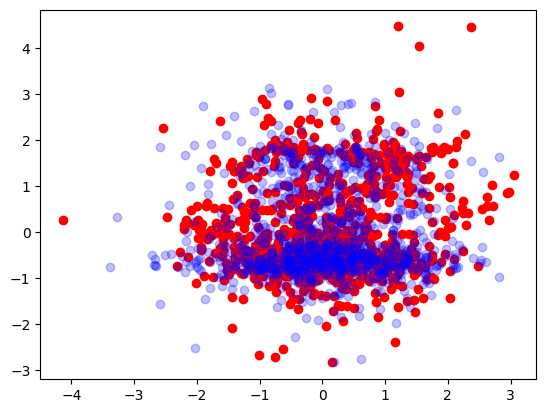

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


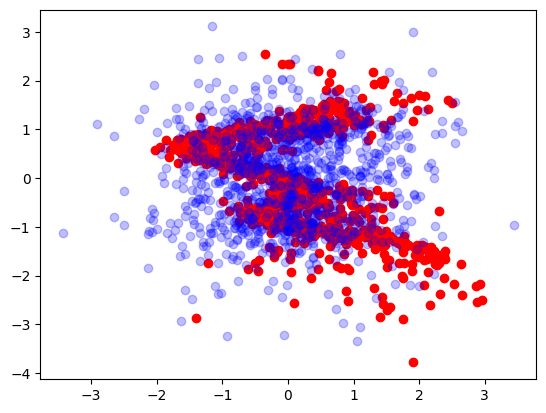

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


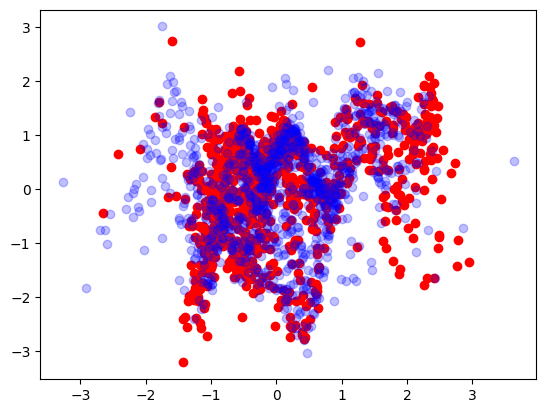

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


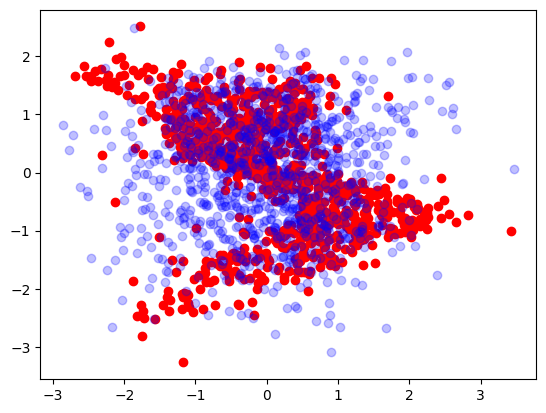

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


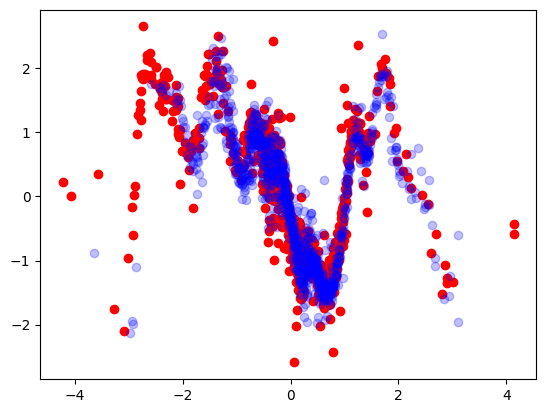

<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks,
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(variable_counts, intvn_indices)

    plt.scatter(
        obs_data_array[0][:, intvn_indices[0]],
        obs_data_array[0][:, outcome_index[0]],
        c="r",
    )

    plt.scatter(
        int_data_array[0][:, intvn_indices[0]],
        int_data_array[0][:, outcome_index[0]],
        c="b",
        alpha=0.25,
    )
    print("Causal graph:", causal_graphs_array[0])
    print("Intervention:", intvn_indices[0])
    print("Outcome:", outcome_index[0])
    plt.show()
    plt.clf()
